# Telco Customer Churn

In [1]:
# Imports

import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# - LogisticRegression: Cria um modelo de regressão logística para classificação, estimando a probabilidade de uma observação pertencer a uma classe.

# - StratifiedKFold: Divide os dados em k partes, preservando aproximadamente a proporção das classes em cada parte.

# - cross_val_score: Avalia o modelo por validação cruzada e retorna a métrica de desempenho obtida em cada divisão.

# - train_test_split: Divide os dados em conjuntos de treino e teste para treinar e avaliar o modelo em observações separadas.

# - Pipeline: Encadeia etapas de processamento e modelagem, executando-as sequencialmente e ajudando a evitar vazamento de dados (data leakage).

# - OneHotEncoder: Transforma variáveis categóricas em colunas binárias, representando cada categoria com um indicador.

# - StandardScaler: Padroniza variáveis numéricas para terem média 0 e desvio-padrão 1, calculados nos dados usados no ajuste.

# - ColumnTransformer: Aplica transformações diferentes a grupos específicos de colunas, como padronizar variáveis numéricas e codificar categóricas.

# - SimpleImputer: Preenche valores ausentes usando uma estratégia definida, como média, mediana, valor mais frequente ou uma constante.

In [2]:
# Carregar dados

dados = pd.read_csv(r"data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
dados.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
# Coluna TotalCharges deve ser convertida para numeric
dados['TotalCharges'] = pd.to_numeric(dados['TotalCharges'], errors="coerce")

In [21]:
numericos = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
categoricos = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']
target = ['Churn']

In [22]:
dados.isna().sum().sort_values(ascending=False)

TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
StreamingMovies      0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
Churn                0
dtype: int64

In [24]:
dados.loc[dados["TotalCharges"].isna(), ["tenure", "MonthlyCharges"]]

,tenure,MonthlyCharges
488,0,52.55
753,0,20.25
936,0,80.85
1082,0,25.75
1340,0,56.05
3331,0,19.85
3826,0,25.35
4380,0,20.00
5218,0,19.70
6670,0,73.35


In [23]:
# Vamos usar One-Hot Encoder para as categóricas e StandardScaler para as numericas (x-media/sd) e Imputer para os valores faltantes.
# Devemos fazer isso somente nos dados de TREINO para não haver data_leakage (padronizarmos com os valores provenientes de dados de teste)

pre = ColumnTransformer([
    ("numericos", Pipeline([
        ("imputer", SimpleImputer(strategy="median")), # nos dados faltantes de 'TotalCharges'
        ("scaler", StandardScaler()) # padroniza
    ]), numericos), # nome > pipe > dados
    ("categoricos", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")), # se faltar dados nas categorias, troca pelo valor mais frequente
        ("onehot", OneHotEncoder(handle_unknown="ignore")) # se no teste aparecer algum valor que não existia no treino ele ignora
    ]), categoricos) # nome > pipe > dados
])

modelo = Pipeline([
    ("pre", pre), ("classifier", LogisticRegression(max_iter = 10_000)) # ajusta os dados e depois passa para o modelo
])

# Até aqui apenas definimos o roteiro, agora precisamos separar os dados que irão entrar na história

X = dados[numericos + categoricos] # sem a target aqui
y = dados['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1) # Separa treino e teste na prop 80/20, stratify=y mantém as proporcoes de y no treino e teste

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)

scores = cross_val_score(modelo, X_train, y_train, cv = cv, scoring= "roc_auc") # avaliamos o modelo treinado com X_train e y_train usando Cross Validation (imagem abaixo)

print(scores.mean(), scores.std())

0.8475350880505312 0.015957111550020855


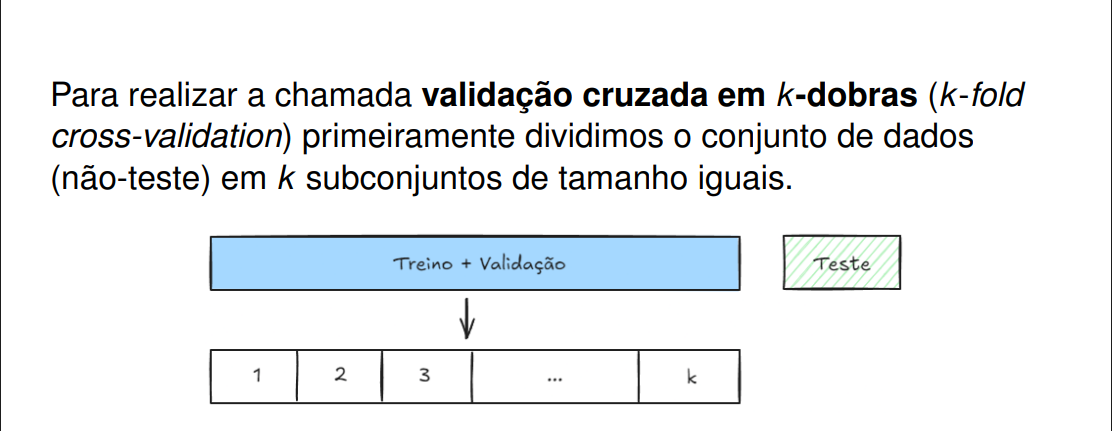

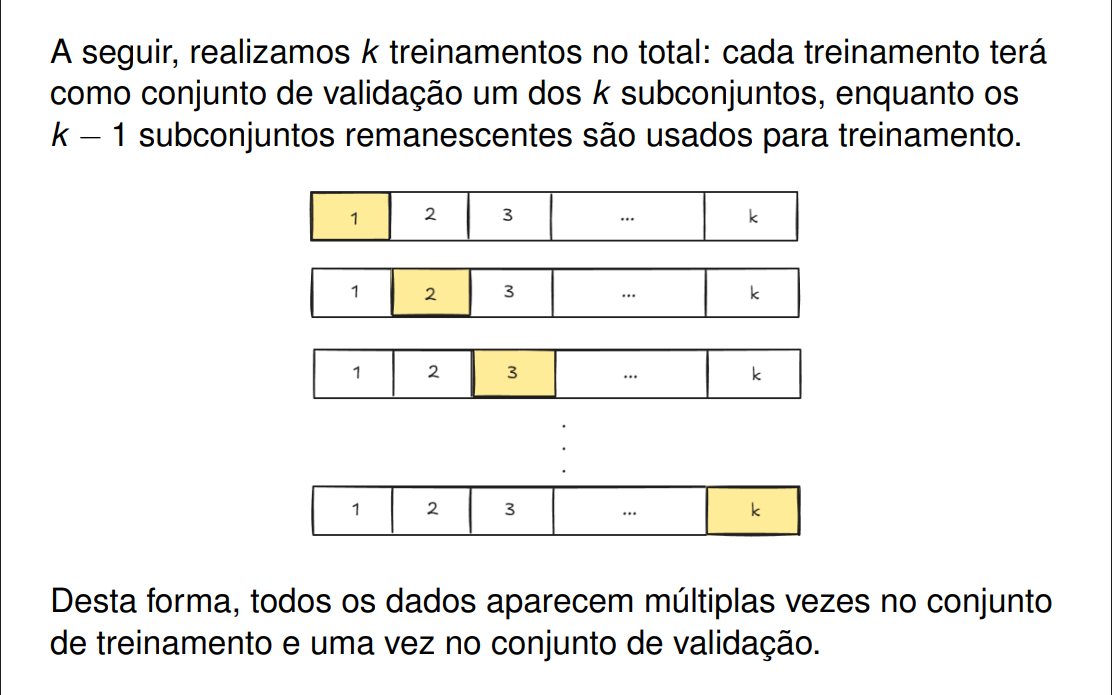